# Metallic (block3D) Plate in Ferrite     

## Import Packages 

In [30]:
using Ferrite
using FerriteGmsh
using SparseArrays
using LinearAlgebra 
using HCubature      # provides adaptive numerical integration 
using WriteVTK
using Plots 

In [69]:
# some functionality (e.g. the documentation of RefHexahdron) is missing in newer versions 
# of Ferrite under newer versions of Julia (to be made clear)
pkgversion(Ferrite)

v"1.0.0"

## Section 1: Introduction 

We discuss functionality of [Ferrite.jl](https://ferrite-fem.github.io/Ferrite.jl/stable/)
to implement a Galerkin Method of Moments method. The geometry of a 3D plate (block3D) is used. Linear shape functions on a mesh of tetrahedra are employed, i.e., <i>order=1</i> and <i>ip = Lagrange{RefTetrahedron, order}()</i>. 

We intend to employ Ferrite.jl to construct the load vector (classical FEM), the sparse mass matrix (as in classical FEM) and the dense stiffness matrix (resulting from the integro-differential equation). The latter consists of a volume-volume term, a surface-surface term and a volume-surface term (and its transpose). 

Observe that Ferrite provides the connectivity between nodes, edges, facets and elements that we require. We intend to exploit this functionality to apply dimension reduction (Euler integration theorem for homogeneous functions) to treat the singular six-dimensional integrals. 

In [54]:
#?RefHexahedron

In [33]:
?RefTetrahedron

search: RefTetrahedron



```
RefTetrahedron <: AbstractRefShape{3}
```

Reference tetrahedron, reference dimension 3.

```
---------------------------------------+-------------------------
Vertex numbers:                        | Vertex coordinates:
             4                4        |
  ^ ξ₃      /  \             /| \      |  v1: 𝛏 = (0.0, 0.0, 0.0)
  |        /     \          / |   \    |  v2: 𝛏 = (1.0, 0.0, 0.0)
  +-> ξ₂  /        \       /  1___  \  |  v3: 𝛏 = (0.0, 1.0, 0.0)
 /       /      __--3     / /    __‾-3 |  v4: 𝛏 = (0.0, 0.0, 1.0)
ξ₁      2 __--‾‾         2/__--‾‾      |
---------------------------------------+-------------------------
Edge numbers:                          | Edge identifiers:
             +                +        | e1: (v1, v2)
            /  \             /| \      | e2: (v2, v3)
         5 /     \ 6      5 / |4  \ 6  | e3: (v3, v1)
          /        \       /  +__3  \  | e4: (v1, v4)
         /      __--+     / /1   __‾-+ | e5: (v2, v4)
        + __--‾‾2        +/__--‾‾2     | e6: (v3, v4)
---------------------------------------+-------------------------
Face numbers:                          | Face identifiers:
             +                +        |
            /  \             /| \      | f1: (v1, v3, v2)
           /     \          / | 4 \    | f2: (v1, v2, v4)
          /   3    \       /2 +___  \  | f3: (v2, v3, v4)
         /      __--+     / /  1 __‾-+ | f4: (v1, v4, v3)
        + __--‾‾         +/__--‾‾      |
---------------------------------------+-------------------------
```


## Section 2: Auxiliary Functionality  

In [34]:
function integrate_tet(f, cell_cache; rtol=1e-8, atol=1e-8)
    coord = getcoordinates(cell_cache)
    p1 = coord[1]; p2 = coord[2]; 
    p3 = coord[3]; p4 = coord[4]; 
    # Compute the geometric Jacobian matrix and its determinant
    # This maps the reference simplex to the physical tetrahedron
    J_geom_mat = hcat(p2 .- p1, p3 .- p1, p4 .- p1)
    jac_geom = abs(det(J_geom_mat))
    
    # Define the transformed integrand over the unit cube [0, 1]^3
    function unit_cube_integrand(t)
        x, y, z = t[1], t[2], t[3]
        
        # Duffy transformation: unit cube -> reference simplex coordinates
        u = x
        v = y * (1.0 - x)
        w = z * (1.0 - x) * (1.0 - y)
        
        # Map reference coordinates to the physical tetrahedron space
        p = p1 .+ u .* (p2 .- p1) .+ v .* (p3 .- p1) .+ w .* (p4 .- p1)
        
        # Internal transformation Jacobian scaling factor
        jac_ref = (1.0 - x)^2 * (1.0 - y)
        
        return f(p) * jac_geom * jac_ref
    end
    
    # Integrate over the hypercube [0,0,0] to [1,1,1]
    val, err = hcubature(unit_cube_integrand, [0.0, 0.0, 0.0], [1.0, 1.0, 1.0], rtol=rtol, atol=atol)
    return val
end; 

## Section 3: Generate the Mesh  
1. Note that <i>nelem = 3; nels  = (nelem, nelem, nelem)</i> results in <i>3^3 = 81</i> quadrilateral cells and thus in <i>2*3^3 = 2*81 = 162</i> tetrahedral cells and <i>6*2*3*3 = 108</i> boundary facets; 

In [80]:
nelem = 3 
nels  = (nelem, nelem, nelem) # number of elements in each spatial direction
left  = Vec((0., 0., 0.))    # start point for geometry 
right = Vec((1.0, 1.0, 1.0)) # end point for geometry
grid  = generate_grid(Tetrahedron,nels,left,right);
# All external boundaries
bndset = union(getfacetset(dh.grid, "left"), getfacetset(dh.grid, "right"),
               getfacetset(dh.grid, "top"), getfacetset(dh.grid, "bottom"),
               getfacetset(dh.grid, "front"), getfacetset(dh.grid, "back"));

In [47]:
# loop over cell 
#for (ic,cell) in enumerate(grid.cells) println(" ic = ", ic, " cell = ", cell) end

In [50]:
# loop over boundary facets 
#for (jf,face) in enumerate(bndset)  println(" jf = ", jf, " face = ", face) end

In [82]:
# get number of nodes in the grid - for memory allocation of global matrix 
#getnnodes(grid)

## Section 4: CellIterator, FacetIterator, Cellid, Nodal Coordinates and Global Indices  

We introduce the CellIterator and the FacetIterator. This requires to define the DofHandler and to add at least one field to it. 

In [72]:
order = 1
ip = Lagrange{RefTetrahedron, order}()
dh = DofHandler(grid)
# add of one field to prevent dh from being empty 
add!(dh, :u, ip)
close!(dh)

for (ic, cell_cache) in enumerate(CellIterator(dh)) 
    
    # 1. Obtain the cellid of this cell 
    thiscellid = cellid(cell_cache)
    
    # 2. Get the indices of the nodes for this cell
    nodes = getnodes(cell_cache)  

    # 3. Get the physical coordinates for this cell 
    # (as a vector of Vec objects - one vector of coordinates per node)
    coords = getcoordinates(cell_cache) 
    
    cell = getcells(dh.grid, cellid(cell_cache))
    coords = getcoordinates(cell_cache)
    
    if (false) 
       println("typeof(cell_cache) = \n", typeof(cell_cache))
       println("typeof(cell)       = \n", typeof(cell))
    end      
end

In [26]:
for face_cache in FacetIterator(dh, bndset)
    
    if (false)
       println("typeof(face_cache) = \n", typeof(face_cache))
    end      
        
end

## Section 5: Shape Function and Shape Function Gradient 

We access the shape functions and the shape function gradients of cells in the volume. We therefore introduce CellValue and the function <i>reinit!</i>. We also access the shape functions of facets on the boundary.  

### For cells 

In [110]:
order = 1
ip = Lagrange{RefTetrahedron, order}()
qr = QuadratureRule{RefTetrahedron}(1)
cellvalues = CellValues(qr, ip);
dh = DofHandler(grid)
# add of one field to prevent dh from being empty 
add!(dh, :u, ip)
close!(dh)

for (ic,cell_cache) in enumerate(CellIterator(dh)) 
    reinit!(cellvalues, cell_cache) 
    
    # Linear elements have a constant Jacobian, so we can just look at quadrature point 1
    q_point = 1 
    
    # 1. Get the Jacobian Matrix (Returns a 1×1 Tensor{1, 1, Float64})
    # Note: Ferrite relies on Tensors.jl for this type
    this_shape_value = Ferrite.shape_value(cellvalues,q_point,2)
    this_shape_grad  = Ferrite.shape_gradient(cellvalues,q_point,2)
    
    if (ic==2)
        display(this_shape_grad)
    end 
    
end

3-element Vec{3, Float64}:
  0.0
 -3.0
  3.0

In [79]:
order = 1
ip = Lagrange{RefTetrahedron, order}()
qr = QuadratureRule{RefTetrahedron}(1)
cellvalues = CellValues(qr, ip);
dh = DofHandler(grid)
# add of one field to prevent dh from being empty 
add!(dh, :u, ip)
close!(dh)
 
v = zeros(12)

for cell_cache in CellIterator(dh)
    irng = [1,5,9]
    
    reinit!(cellvalues, cell_cache) 
    
    # Linear elements have a constant Jacobian, so we can just look at quadrature point 1
    q_point = 1 

    for i in 1:getnbasefunctions(cellvalues)
        this_shape_grad = Ferrite.shape_gradient(cellvalues,q_point,i)
        v[irng] .= this_shape_grad
        irng .+= 1
    end
    
end 

### For Facets 

In [ ]:
for fc in FacetIterator(dh, getfacetset(grid, "right"))
    reinit!(fv, fc)
    fill!(fe, 0)
    for q_point in 1:getnquadpoints(fv)
        dΓ = getdetJdV(fv, q_point)
        for i in 1:getnbasefunctions(fv)
            δu = shape_value(fv, q_point, i)
            fe[i] += δu * qn * dΓ
        end
    end
    assemble!(f, celldofs(fc), fe)
end

## Section 6: Volume - Volume Interactions 

In [64]:
kernel(rd, rs) = 1/(norm(rd - rs)+1e-9)

order = 1
ip = Lagrange{RefTetrahedron, order}()
dh = DofHandler(grid)
# add of one field to prevent dh from being empty 
add!(dh, :u, ip)
close!(dh)

function volvol(dh)

    Nc = length(CellIterator(dh))
    A = zeros(Nc,Nc)     
    for (ic,cell_cache) in enumerate(CellIterator(dh))
        
        println("ic = \n", ic)
            
        for (icp, cell_cachep) in enumerate(CellIterator(dh))
            inner_integral(rd) = integrate_tet(rs->kernel(rd,rs), cell_cachep)
            outer_integral = integrate_tet(rd->inner_integral(rd), cell_cache)
            A[ic,icp] = outer_integral 
        end 
    
    end
     
    return A 
    
end
  
A = volvol(dh)

ic = 
1
ic = 
2
ic = 
3
ic = 
4
ic = 
5
ic = 
6
ic = 
7
ic = 
8
ic = 
9
ic = 
10
ic = 
11
ic = 
12
ic = 
13
ic = 
14
ic = 
15
ic = 
16
ic = 
17
ic = 
18
ic = 
19
ic = 
20
ic = 
21
ic = 
22
ic = 
23
ic = 
24
ic = 
25
ic = 
26
ic = 
27
ic = 
28
ic = 
29
ic = 
30
ic = 
31
ic = 
32
ic = 
33
ic = 
34
ic = 
35
ic = 
36
ic = 
37
ic = 
38
ic = 
39
ic = 
40
ic = 
41
ic = 
42
ic = 
43
ic = 
44
ic = 
45
ic = 
46
ic = 
47
ic = 
48
ic = 
49
ic = 
50
ic = 
51
ic = 
52
ic = 
53
ic = 
54
ic = 
55
ic = 
56
ic = 
57
ic = 
58
ic = 
59
ic = 
60
ic = 
61
ic = 
62
ic = 
63
ic = 
64
ic = 
65
ic = 
66
ic = 
67
ic = 
68
ic = 
69
ic = 
70
ic = 
71
ic = 
72
ic = 
73
ic = 
74
ic = 
75
ic = 
76
ic = 
77
ic = 
78
ic = 
79
ic = 
80
ic = 
81
ic = 
82
ic = 
83
ic = 
84
ic = 
85
ic = 
86
ic = 
87
ic = 
88
ic = 
89
ic = 
90
ic = 
91
ic = 
92
ic = 
93
ic = 
94
ic = 
95
ic = 
96
ic = 
97
ic = 
98
ic = 
99
ic = 
100
ic = 
101
ic = 
102
ic = 
103
ic = 
104
ic = 
105
ic = 
106
ic = 
107
ic = 
108
ic = 
109
ic = 
110
ic = 
11

162×162 Matrix{Float64}:
 0.000348152  0.000233927  0.000233927  …  3.00359e-5   2.80812e-5
 0.000233927  0.000348151  0.000163616     3.02982e-5   2.81868e-5
 0.000233926  0.000163616  0.000348152     3.21412e-5   3.00359e-5
 0.000163616  0.000147786  0.000233926     3.53376e-5   3.27602e-5
 0.000163615  0.000233926  0.000147786     3.2796e-5    3.02979e-5
 0.000147786  0.000163615  0.000163616  …  3.57661e-5   3.29294e-5
 0.000112124  0.000105829  0.000147748     3.45937e-5   3.23318e-5
 0.000105829  0.000112115  0.000119842     3.50006e-5   3.24972e-5
 8.79769e-5   8.23201e-5   0.000114805     3.69238e-5   3.45942e-5
 7.28051e-5   7.12393e-5   8.79771e-5      4.0732e-5    3.79228e-5
 8.23203e-5   8.79771e-5   9.20557e-5   …  3.79223e-5   3.50008e-5
 7.12392e-5   7.28049e-5   8.23206e-5      4.13786e-5   3.81868e-5
 5.69387e-5   5.60728e-5   6.49597e-5      3.74769e-5   3.54646e-5
 ⋮                                      ⋱  ⋮            
 3.81863e-5   3.79226e-5   4.13776e-5   …  8.23

In [62]:
length(CellIterator(dh))

162

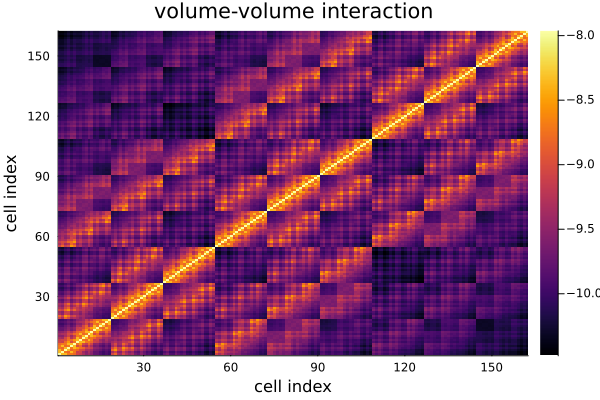

In [71]:
heatmap(log.(abs.(A)), xlabel="cell index", ylabel="cell index", title="volume-volume interaction")

In [106]:
order = 1
ip = Lagrange{RefTetrahedron, order}()
qr = QuadratureRule{RefTetrahedron}(1)
cellvalues  = CellValues(qr, ip)
cellvaluesp = CellValues(qr, ip)
dh = DofHandler(grid)
# add of one field to prevent dh from being empty 
add!(dh, :u, ip)
close!(dh)

function volvolpercell(cellvalues, cellvaluesp)

    v  = zeros(12)
    vp = zeros(12)
    irng = [1,5,9]
    
    # Linear elements have a constant Jacobian, so we can just look at quadrature point 1
    q_point = 1 

    for i in 1:getnbasefunctions(cellvalues)
        this_shape_grad = Ferrite.shape_gradient(cellvalues,q_point,i)
        v[irng]        .= this_shape_grad
        this_shape_grad = Ferrite.shape_gradient(cellvaluesp,q_point,i)
        vp[irng]       .= this_shape_grad
        irng .+= 1
    end
    
    return vp*Transpose(v), v, vp 
end 

function volvol2(dh)
    
    #..initialize global matrix 
    Nn = getnnodes(Ferrite.get_grid(dh))
    A = zeros(3*Nn,3*Nn)   
    
    #..outer double loop over cells in volume  
    for (ic,cell_cache) in enumerate(CellIterator(dh))
        
        # println("ic = \n", ic)
        reinit!(cellvalues, cell_cache)
        nodes  = getnodes(cell_cache)
        bnodes = vcat(nodes, nodes.+Nn, nodes.+2*Nn)
        
        #..inner double loop over cells in volume
        for (icp, cell_cachep) in enumerate(CellIterator(dh))
            # println("ic = ", ic, " icp = ", icp, "\n")
            reinit!(cellvaluesp, cell_cachep)
            nodesp = getnodes(cell_cachep)
            bnodesp = vcat(nodes, nodes.+Nn, nodes.+2*Nn)
            Aloc,v,vp = volvolpercell(cellvalues, cellvaluesp)
            A[bnodes,bnodesp] += Aloc 
            if ((ic==1)&&(icp==1)) 
                display(v)
                display(vp)
                display(Aloc)
            end 
        end 
    
    end
     
    return A 
    
end

A = volvol2(dh)

# heatmap(log.(abs.(A)), xlabel="cell index", ylabel="cell index", title="volume-volume interaction")

12-element Vector{Float64}:
 -3.0
  3.0
  0.0
  0.0
 -3.0
  0.0
  3.0
  0.0
  0.0
  0.0
 -3.0
  3.0

12-element Vector{Float64}:
 -3.0
  3.0
  0.0
  0.0
 -3.0
  0.0
  3.0
  0.0
  0.0
  0.0
 -3.0
  3.0

12×12 Matrix{Float64}:
  9.0  -9.0  -0.0  -0.0   9.0  -0.0  -9.0  -0.0  -0.0  -0.0   9.0  -9.0
 -9.0   9.0   0.0   0.0  -9.0   0.0   9.0   0.0   0.0   0.0  -9.0   9.0
 -0.0   0.0   0.0   0.0  -0.0   0.0   0.0   0.0   0.0   0.0  -0.0   0.0
 -0.0   0.0   0.0   0.0  -0.0   0.0   0.0   0.0   0.0   0.0  -0.0   0.0
  9.0  -9.0  -0.0  -0.0   9.0  -0.0  -9.0  -0.0  -0.0  -0.0   9.0  -9.0
 -0.0   0.0   0.0   0.0  -0.0   0.0   0.0   0.0   0.0   0.0  -0.0   0.0
 -9.0   9.0   0.0   0.0  -9.0   0.0   9.0   0.0   0.0   0.0  -9.0   9.0
 -0.0   0.0   0.0   0.0  -0.0   0.0   0.0   0.0   0.0   0.0  -0.0   0.0
 -0.0   0.0   0.0   0.0  -0.0   0.0   0.0   0.0   0.0   0.0  -0.0   0.0
 -0.0   0.0   0.0   0.0  -0.0   0.0   0.0   0.0   0.0   0.0  -0.0   0.0
  9.0  -9.0  -0.0  -0.0   9.0  -0.0  -9.0  -0.0  -0.0  -0.0   9.0  -9.0
 -9.0   9.0   0.0   0.0  -9.0   0.0   9.0   0.0   0.0   0.0  -9.0   9.0

192×192 Matrix{Float64}:
  972.0  -972.0     0.0     0.0      0.0  …    0.0     0.0     0.0    0.0
 -972.0  1944.0  -972.0     0.0    486.0       0.0     0.0     0.0    0.0
    0.0  -972.0  1944.0  -972.0      0.0       0.0     0.0     0.0    0.0
    0.0     0.0  -972.0   972.0      0.0       0.0     0.0     0.0    0.0
 -486.0   486.0     0.0     0.0    486.0       0.0     0.0     0.0    0.0
    0.0  -486.0   486.0     0.0  -1458.0  …    0.0     0.0     0.0    0.0
    0.0     0.0  -486.0   486.0      0.0       0.0     0.0     0.0    0.0
    0.0     0.0     0.0     0.0      0.0       0.0     0.0     0.0    0.0
    0.0     0.0     0.0     0.0   -486.0       0.0     0.0     0.0    0.0
    0.0     0.0     0.0     0.0      0.0       0.0     0.0     0.0    0.0
    0.0     0.0     0.0     0.0      0.0  …    0.0     0.0     0.0    0.0
    0.0     0.0     0.0     0.0      0.0       0.0     0.0     0.0    0.0
    0.0     0.0     0.0     0.0      0.0       0.0     0.0     0.0    0.0
    ⋮        

In [92]:
a = [1, 2] 
b = vcat(a, a.+5, a.+10)

6-element Vector{Int64}:
  1
  2
  6
  7
 11
 12

## Section 20: Read Mesh from File 

### Read Mesh and Perform Elementary Checks 

In [26]:
meshfile = "metallic_plate_3d.msh"
grid = togrid(meshfile)

Info    : Reading 'metallic_plate_3d.msh'...
Info    : 27 entities
Info    : 108 nodes
Info    : 474 elements
Info    : Done reading 'metallic_plate_3d.msh'


Grid{3, Tetrahedron, Float64} with 262 Tetrahedron cells and 108 nodes

In [27]:
# what is the mesh size?  
dh = DofHandler(grid)
order = 1
ip = Lagrange{RefTetrahedron, order}()
add!(dh, :u, ip)
close!(dh)
K = allocate_matrix(dh)

108×108 SparseMatrixCSC{Float64, Int64} with 1058 stored entries:
⎡⣿⣿⡇⠀⠀⠖⠲⣂⡖⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠤⠀⠀⠀⠀⠀⎤
⎢⠉⠉⢱⣶⣦⡄⠉⠀⠁⠀⠀⠰⠢⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⢀⠄⠀⠀⣠⠀⠀⠀⠄⠄⠉⠈⠠⠠⠀⠀⎥
⎢⢠⠄⠈⠿⠿⣧⣤⠀⠀⠀⠀⠈⠙⠁⠀⠄⠠⠀⠀⠀⠀⢠⡀⡄⠠⠆⠀⠀⠠⠀⠀⠀⠀⠂⠄⠀⠀⠐⠀⠀⎥
⎢⠸⢢⠃⠀⠀⠛⠛⣤⣤⠀⠀⠀⠀⠀⠀⠀⠐⠀⠀⠀⠀⠀⠒⢂⡀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠂⠐⠀⠀⠀⠀⎥
⎢⠘⠉⠁⠀⠀⠀⠀⠛⠛⣤⣤⡄⠀⠠⠄⠄⠀⠀⠀⠀⠁⠁⠀⠐⠃⠀⠔⠣⠀⠀⠀⠀⠀⠀⠈⠀⠀⠀⠀⠀⎥
⎢⠀⠀⢀⡀⡀⠀⠀⠀⠀⠿⠿⢇⣀⡐⠓⡂⢀⠁⠀⠃⠀⠀⠀⠀⠀⠸⠄⠨⠀⠀⠀⠀⠀⠀⠀⠀⢀⢘⢁⡀⎥
⎢⠀⠀⠈⠂⠗⠀⠀⠀⠀⡀⢀⠸⠿⢇⣀⡮⠭⠀⠀⢀⣀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠐⠀⠂⎥
⎢⠀⠀⠀⠀⠀⠄⠀⠀⠀⠅⠹⠠⡠⡼⠿⣧⣤⠀⠀⠀⠗⢦⠀⡄⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠄⠀⠀⠨⠁⠍⎥
⎢⠀⠀⠀⠀⠀⠂⠐⠀⠀⠀⠄⠐⠃⠃⠀⠛⠛⣤⣄⡄⠀⠈⠉⠃⠀⢀⠀⢠⠀⠀⠁⠠⠀⡀⠂⠐⠄⠀⠔⠂⎥
⎢⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠤⠀⠀⢀⠀⠀⠀⠽⠿⢇⣀⠀⠀⠀⠀⠠⢄⡠⠀⠀⠸⠫⠀⢄⠀⠀⠄⠤⠄⠀⎥
⎢⠀⠀⠀⠀⠀⣀⠀⠀⠅⠀⠀⠀⠀⠘⠹⣅⡀⠀⠀⠘⠿⢇⡀⡐⠇⠀⠀⠃⠀⠀⡀⠀⠀⠐⠨⠀⠀⠀⠀⠍⎥
⎢⠀⠀⠀⠀⠀⠬⠸⢀⢀⠀⠀⠀⠀⠀⠀⠤⠧⠀⠀⠀⢀⠨⠿⢇⡀⠀⢀⡀⠀⠀⠇⠀⠀⢀⠀⠀⠀⠀⠀⠀⎥
⎢⠀⠀⠀⠔⠠⠆⠀⠈⠉⠀⣀⡀⠀⠀⠀⠀⠀⢀⠀⡀⠉⠁⠀⠈⠱⢆⡀⢁⠲⠶⠀⠀⠤⡌⠀⠀⠀⠀⠀⠀⎥
⎢⠀⠀⠀⠀⠀⠀⠀⠀⠴⡁⡀⡁⠀⠀⠀⠀⠀⣀⠀⡱⠤⠀⠀⠰⠄⢈⡱⢎⠀⠀⠀⠀⠀⡱⠀⠀⠀⠀⠀⠀⎥
⎢⠀⠀⠀⠚⠀⠂⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⢸⡆⠀⠀⠿⣧⠠⢀⢶⡀⠀⠀⠀⠀⠀⠀⎥
⎢⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠁⡀⡶⡂⠀⠈⠉⠁⠀⠀⠀⠀⠀⢂⢱⣶⢒⡂⠀⠀⡂⠂⠀⠀⎥
⎢⠀⠀⠀⠅⠠⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠠⠀⢄⢀⠀⠀⢀⡀⠧⢄⡠⠘⠳⠸⠰⠿⢇⠀⠀⠬⠥⠀⠀⎥
⎢⠀⠃⡃⠀⠀⠁⢈⠀⠂⠀⠀⠀⠀⠀⠀⠁⢈⠀⠀⠀⠂⠂⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⣿⣿⡦⠤⢬⠷⎥
⎢⠀⠀⠀⡂⢀⠀⠀⠀⠀⠀⣀⢐⢀⠀⡀⡀⠀⠁⠀⡅⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠨⠈⠆⡇⠈⡏⣿⣿⡝⡃⎥
⎣⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠁⠰⠠⠀⡅⠄⠰⠁⠀⠁⡄⠄⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⢦⡗⠷⠩⡵⣯⎦

### Form Array of Boundary Nodes 

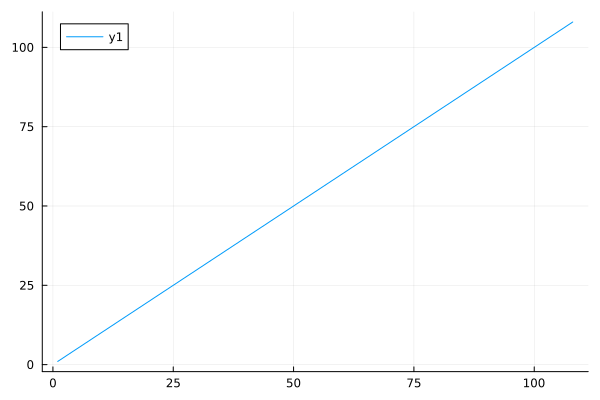

In [28]:
# are boundary nodes correctly identified? 
# is rhs-vector set to Dirichlet value on the boundary nodes? 
∂Ω = getfacetset(grid, "Gamma")

dbc = Dirichlet(:u, ∂Ω, (x, t) -> 0)
ch  = ConstraintHandler(dh);
add!(ch, dbc);
close!(ch)

f = ones(ndofs(dh));

apply!(K, f, ch)

plot(f)

bnd_nodes = findall(f .== 0)

plot(bnd_nodes)

## Section 21: Iterate over Elements in the Mesh 

### Set cellvalues as mandatory for future tests

In [29]:
qr = QuadratureRule{RefTetrahedron}(2*order+1) # number of quadrature points
cellvalues = CellValues(qr, ip);

### Loop over facets belonging to a cell 

In [31]:
cell_id = 42
cell = grid.cells[cell_id]

# 1. Get total number of faces/facets for this element type
num_faces = nfacets(cell)

# 2. Generate all Face/Facet Indices for this element
cell_faces = [FacetIndex(cell_id, local_face_id) for local_face_id in 1:num_faces]

4-element Vector{FacetIndex}:
 FacetIndex((42, 1))
 FacetIndex((42, 2))
 FacetIndex((42, 3))
 FacetIndex((42, 4))

In [33]:
cell_edges = [EdgeIndex(cell_id, local_edge_id) for local_edge_id in 1:6]

6-element Vector{EdgeIndex}:
 EdgeIndex((42, 1))
 EdgeIndex((42, 2))
 EdgeIndex((42, 3))
 EdgeIndex((42, 4))
 EdgeIndex((42, 5))
 EdgeIndex((42, 6))

### Loop over edges belonging to a facet 

In [34]:
?Ferrite.facets

!!! warning
    The following bindings may be internal; they may change or be removed in future versions:

      * `Ferrite.facets`


```julia
Ferrite.facets(::AbstractCell)
```

Returns a tuple of n-tuples containing the ordered node indices (of the nodes in a grid) corresponding to the vertices that define an oriented facet. This function induces the [`FacetIndex`](@ref), where the second index corresponds to the local index into this tuple.

See also [`vertices`](@ref), [`edges`](@ref), and [`faces`](@ref)


In [35]:
cell_id = 42
cell = grid.cells[cell_id]

# 1. Choose your local face ID (e.g., face 1)
local_face_id = 1
# Get the local node indices making up this face
face_nodes = Ferrite.facetv(cell)[local_face_id] # e.g., (1, 2, 6, 5)

# 2. Get all edges for this cell type
cell_edges = Ferrite.edges(cell) # Returns a tuple of vertex pairs, e.g., ((1,2), (2,3), ...)

# 3. Find which cell edges are composed entirely of this face's nodes
face_edges = Int[]
for (local_edge_id, edge_vertices) in enumerate(cell_edges)
    # If both vertices of the edge lie on the face, this edge belongs to the face
    if edge_vertices[1] in face_nodes && edge_vertices[2] in face_nodes
        push!(face_edges, local_edge_id)
    end
end

# Now `face_edges` contains the local edge IDs belonging to the chosen face
# You can wrap them into EdgeIndex structs:
edge_indices = [EdgeIndex(cell_id, e_id) for e_id in face_edges]

LoadError: UndefVarError: `facetv` not defined in `Ferrite`
Suggestion: check for spelling errors or missing imports.

## Section 22: Combining Ferrite.jl and HCubature.jl 

reinit!(cv::AbstractCellValues, cell::Union{Nothing, Ferrite.AbstractCell}, x::AbstractVector{<:Vec}) 

in Ferrite at /Users/dlahaye/.julia/packages/Ferrite/e5O5M/src/FEValues/CellValues.jl:122

function reinit!(cv::CellValues, x::AbstractVector{Vec{dim, T}}, ξ::Vec{ref_dim, T}) where {dim, ref_dim, T}


In [6]:
methods(Ferrite.reinit!)

# 17 methods for generic function "reinit!" from Ferrite:
  [1] reinit!(fv::FacetValues, fc::FacetCache)
     @ ~/.julia/packages/Ferrite/e5O5M/src/iterators.jl:153
  [2] reinit!(fv::FacetValues, cc::CellCache, f::Integer)
     @ ~/.julia/packages/Ferrite/e5O5M/src/iterators.jl:94
  [3] reinit!(fv::FacetValues, cell::Union{Nothing, Ferrite.AbstractCell}, x::AbstractArray{Vec{dim, T}, 1}, facet_nr::Int64) where {dim, T}
     @ ~/.julia/packages/Ferrite/e5O5M/src/FEValues/FacetValues.jl:129
  [4] reinit!(cache::InterfaceCache, facet_a::Ferrite.BoundaryIndex, facet_b::Ferrite.BoundaryIndex)
     @ ~/.julia/packages/Ferrite/e5O5M/src/iterators.jl:188
  [5] reinit!(fc::FacetCache, facet::Ferrite.BoundaryIndex)
     @ ~/.julia/packages/Ferrite/e5O5M/src/iterators.jl:137
  [6] reinit!(pv::PointValues, x::AbstractVector, ξ::Vec)
     @ ~/.julia/packages/Ferrite/e5O5M/src/FEValues/PointValues.jl:67
  [7] reinit!(pv::PointValues, point::PointLocation)
     @ ~/.julia/packages/Ferrite/e5O5M/src/PointEvalHandler.jl:511
  [8] reinit!(pv::PointValues, cell::Union{Nothing, Ferrite.AbstractCell}, x::AbstractVector{<:Vec{sdim}}, ξ::Vec{rdim}) where {sdim, rdim}
     @ ~/.julia/packages/Ferrite/e5O5M/src/FEValues/PointValues.jl:71
  [9] reinit!(fv::AbstractFacetValues, x::AbstractVector, facet_nr::Int64)
     @ ~/.julia/packages/Ferrite/e5O5M/src/FEValues/FacetValues.jl:125
 [10] reinit!(cv::AbstractCellValues, cell::Union{Nothing, Ferrite.AbstractCell}, x::AbstractVector{<:Vec})
     @ ~/.julia/packages/Ferrite/e5O5M/src/FEValues/CellValues.jl:122
 [11] reinit!(cv::MultiFieldCellValues, x::AbstractVector)
     @ ~/.julia/packages/Ferrite/e5O5M/src/FEValues/CellValues.jl:275
 [12] reinit!(cv::AbstractCellValues, x::AbstractVector)
     @ ~/.julia/packages/Ferrite/e5O5M/src/FEValues/CellValues.jl:118
 [13] reinit!(cv::AbstractCellValues, cc::CellCache)
     @ ~/.julia/packages/Ferrite/e5O5M/src/iterators.jl:90
 [14] reinit!(iv::InterfaceValues, cell_here::Ferrite.AbstractCell, coords_here::AbstractArray{Vec{dim, T}, 1}, facet_here::Int64, cell_there::Ferrite.AbstractCell, coords_there::AbstractArray{Vec{dim, T}, 1}, facet_there::Int64, interface_transformation) where {dim, T}
     @ ~/.julia/packages/Ferrite/e5O5M/src/FEValues/InterfaceValues.jl:147
 [15] reinit!(iv::InterfaceValues, cell_here::Ferrite.AbstractCell, coords_here::AbstractArray{Vec{dim, T}, 1}, facet_here::Int64, cell_there::Ferrite.AbstractCell, coords_there::AbstractArray{Vec{dim, T}, 1}, facet_there::Int64) where {dim, T}
     @ ~/.julia/packages/Ferrite/e5O5M/src/FEValues/InterfaceValues.jl:120
 [16] reinit!(iv::InterfaceValues, ic::InterfaceCache)
     @ ~/.julia/packages/Ferrite/e5O5M/src/iterators.jl:201
 [17] reinit!(cc::CellCache, i::Integer)
     @ ~/.julia/packages/Ferrite/e5O5M/src/iterators.jl:72

In [43]:
grid = generate_grid(Line, (5,), Vec((0.0,)), Vec((1.0,)))
dh = DofHandler(grid)
ip = Lagrange{RefLine, 1}() 
add!(dh, :u, ip)
close!(dh)

qr_dummy = QuadratureRule{RefLine}(1) 
cv = CellValues(qr_dummy, ip)

for cell_cache in CellIterator(dh)
    
    cell = getcells(dh.grid, cellid(cell_cache))
        
    # Haal de fysieke coördinaten van de huidige cel op
    x_coords = getcoordinates(cell_cache)
    xi = (x_coords[1][1] + x_coords[2][1])/2
        
    # Herinitialiseer Ferrite 
    println("Type of arg-1 = \n", typeof(cv))
    println("\n Type of arg-2 = \n", typeof(cell_cache))
    println("\n Type of arg-3 = \n", typeof(x_coords))
    Ferrite.reinit!(cv, cell_cache, x_coords)
        
end

Type of arg-1 = 
CellValues{Ferrite.FunctionValues{1, Lagrange{RefLine, 1}, Matrix{Float64}, Matrix{Float64}, Matrix{Vec{1, Float64}}, Matrix{Vec{1, Float64}}, Nothing, Nothing}, Ferrite.GeometryMapping{1, Lagrange{RefLine, 1}, Matrix{Float64}, Matrix{Vec{1, Float64}}, Nothing}, QuadratureRule{RefLine, Vector{Float64}, Vector{Vec{1, Float64}}}, Vector{Float64}}

 Type of arg-2 = 
CellCache{Vec{1, Float64}, Grid{1, Line, Float64}, DofHandler{1, Grid{1, Line, Float64}}, Vector{Int64}, Vector{Int64}, Vector{Int64}, Vector{Vec{1, Float64}}}

 Type of arg-3 = 
Vector{Vec{1, Float64}}


LoadError: MethodError: no method matching reinit!(::CellValues{…}, ::CellCache{…}, ::Vector{…})
The function `reinit!` exists, but no method is defined for this combination of argument types.

[0mClosest candidates are:
[0m  reinit!(::AbstractCellValues, [91m::Union{Nothing, Ferrite.AbstractCell}[39m, ::AbstractVector{<:Vec})
[0m[90m   @[39m [32mFerrite[39m [90m~/.julia/packages/Ferrite/e5O5M/src/FEValues/[39m[90m[4mCellValues.jl:122[24m[39m
[0m  reinit!(::AbstractCellValues, ::CellCache)
[0m[90m   @[39m [32mFerrite[39m [90m~/.julia/packages/Ferrite/e5O5M/src/[39m[90m[4miterators.jl:90[24m[39m
[0m  reinit!([91m::FacetValues[39m, ::CellCache, [91m::Integer[39m)
[0m[90m   @[39m [32mFerrite[39m [90m~/.julia/packages/Ferrite/e5O5M/src/[39m[90m[4miterators.jl:94[24m[39m
[0m  ...


In [20]:
x_coords

LoadError: UndefVarError: `x_coords` not defined in `Main`
Suggestion: check for spelling errors or missing imports.

In [18]:
using Ferrite, SparseArrays, HCubature

# 1. Mesh en DoFHandler opzetten
grid = generate_grid(Line, (5,), Vec((0.0,)), Vec((1.0,)))
dh = DofHandler(grid)
ip = Lagrange{RefLine, 1}() 
add!(dh, :u, ip)
close!(dh)

# 2. Dummy CellValues initialiseren (voor transformaties op willekeurige ξ-punten)
qr_dummy = QuadratureRule{RefLine}(1) 
cv = CellValues(qr_dummy, ip)
n_basefuncs = getnbasefunctions(cv)

# 3. Globale structuren alloceren
K = allocate_matrix(dh)
F = zeros(ndofs(dh))

# Bronterm functie f(x) in het fysieke domein
f_fysisch(x) = x^2

# 4. De Assemblage Loop
assembler = start_assemble(K, F)

for cell in CellIterator(dh)
    # Haal de fysieke coördinaten van de huidige cel op
    x_coords = getcoordinates(cell)
    
    # We definiëren een gecombineerde integrand die zowel Ke als fe berekent.
    # Dit voorkomt dat HCubature de mapping (reinit!) twee keer apart moet uitrekenen.
    function element_integrand(ξ_vec)
        ξ = ξ_vec[1]
        
        # Herinitialiseer Ferrite op het specifieke punt ξ van HCubature
        # Ferrite.reinit!(cv, x_coords, Vec((ξ,)))
        println("Type of arg-1 = \n", typeof(cv))
        println("\n Type of arg-2 = \n", typeof(cell))
        println("\n Type of arg-3 = \n", typeof(Vec((ξ,))))
        Ferrite.reinit!(cv, cell, Vec((ξ,)))
        
end

Type of arg-1 = 
CellValues{Ferrite.FunctionValues{1, Lagrange{RefLine, 1}, Matrix{Float64}, Matrix{Float64}, Matrix{Vec{1, Float64}}, Matrix{Vec{1, Float64}}, Nothing, Nothing}, Ferrite.GeometryMapping{1, Lagrange{RefLine, 1}, Matrix{Float64}, Matrix{Vec{1, Float64}}, Nothing}, QuadratureRule{RefLine, Vector{Float64}, Vector{Vec{1, Float64}}}, Vector{Float64}}

 Type of arg-2 = 
CellCache{Vec{1, Float64}, Grid{1, Line, Float64}, DofHandler{1, Grid{1, Line, Float64}}, Vector{Int64}, Vector{Int64}, Vector{Int64}, Vector{Vec{1, Float64}}}

 Type of arg-3 = 
Vec{1, Float64}


LoadError: MethodError: no method matching reinit!(::CellValues{…}, ::CellCache{…}, ::Vec{…})
The function `reinit!` exists, but no method is defined for this combination of argument types.

[0mClosest candidates are:
[0m  reinit!(::AbstractCellValues, ::CellCache)
[0m[90m   @[39m [32mFerrite[39m [90m~/.julia/packages/Ferrite/e5O5M/src/[39m[90m[4miterators.jl:90[24m[39m
[0m  reinit!([91m::FacetValues[39m, ::CellCache, [91m::Integer[39m)
[0m[90m   @[39m [32mFerrite[39m [90m~/.julia/packages/Ferrite/e5O5M/src/[39m[90m[4miterators.jl:94[24m[39m
[0m  reinit!([91m::PointValues[39m, [91m::AbstractVector[39m, ::Vec)
[0m[90m   @[39m [32mFerrite[39m [90m~/.julia/packages/Ferrite/e5O5M/src/FEValues/[39m[90m[4mPointValues.jl:67[24m[39m
[0m  ...
